In [2]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from matplotlib.patches import Patch
import matplotlib.patches as mpatches
from matplotlib.legend_handler import HandlerLine2D
from matplotlib.ticker import MultipleLocator, FixedLocator
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool
import pandas as pd
import pickle
import scipy
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple#, HandlerTupleVertical

#from nfw_profile_heating import NFWProfile
from cluster_class.cluster_error_prop import Cluster_werr
from functions.statistics_functions import log_lik
from functions.load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from functions.plotting import savefig, paper_plot
from functions.make_constraints_plot import plot_constraint

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
with open('pickled/mcmc_0.001_64_40000_fx0.1_2024-11-13_08-07-26.pkl', 'rb') as h:
    mcmc_output_01 = pickle.load(h)
#with open('pickled/mcmc_0.001_64_40000_2024-10-07_01-57-30.pkl', 'rb') as h:
#    mcmc_output = pickle.load(h)

(170624, 2)


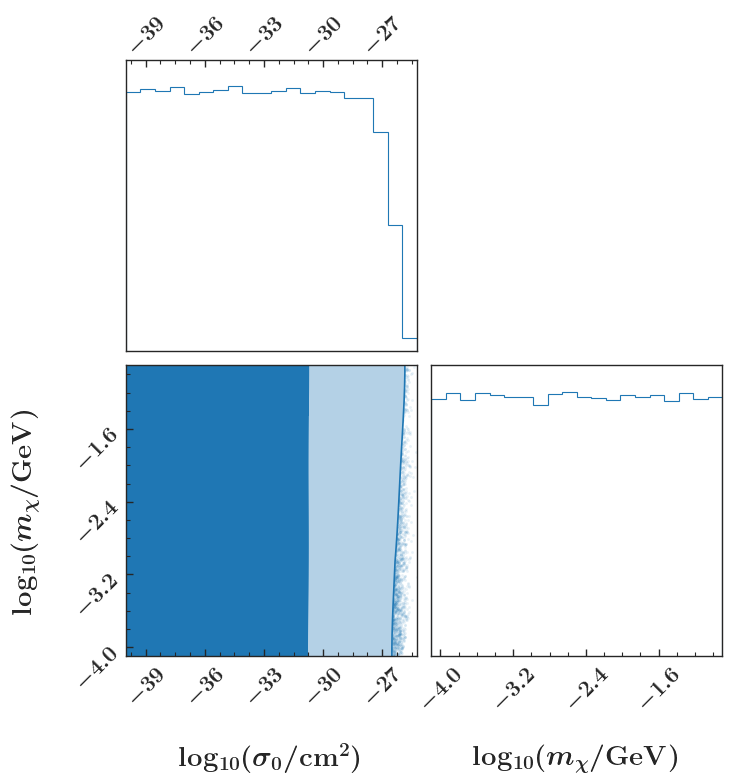

In [4]:
# create corner plot of results
paper_plot()

print(mcmc_output_01.shape)
figure = plt.figure(figsize=(8, 8))



labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_01, 
    labels=labels, 
    dpi=450, 
    smooth=4.5, 
    levels=[0.68, 0.95], 
    top_ticks=True, 
    color='#1f77b4',
    fill_contours=True,
    plot_density=True,
    #contourf_kwargs={"alpha":0.5}, 
    scatter_kws={"alpha": 0}, 
    fig=figure,
    zorder=1
);


# Access the axes of the corner plot
axes = figure.get_axes()

# Enable minor ticks and customize tick parameters for each subplot
for ax in axes:
    ax.minorticks_on()
    ax.tick_params(which='both', direction='in')
    ax.xaxis.set_zorder(10)  
    ax.yaxis.set_zorder(10)  

plt.show()
#savefig(fig, 'plots/corner_plot.png', dpi=450)

In [5]:
with open('pickled/mcmc_0.001_64_40000_fx0.01_2024-11-13_08-02-46.pkl', 'rb') as h:
    mcmc_output_001 = pickle.load(h)

(170624, 2)


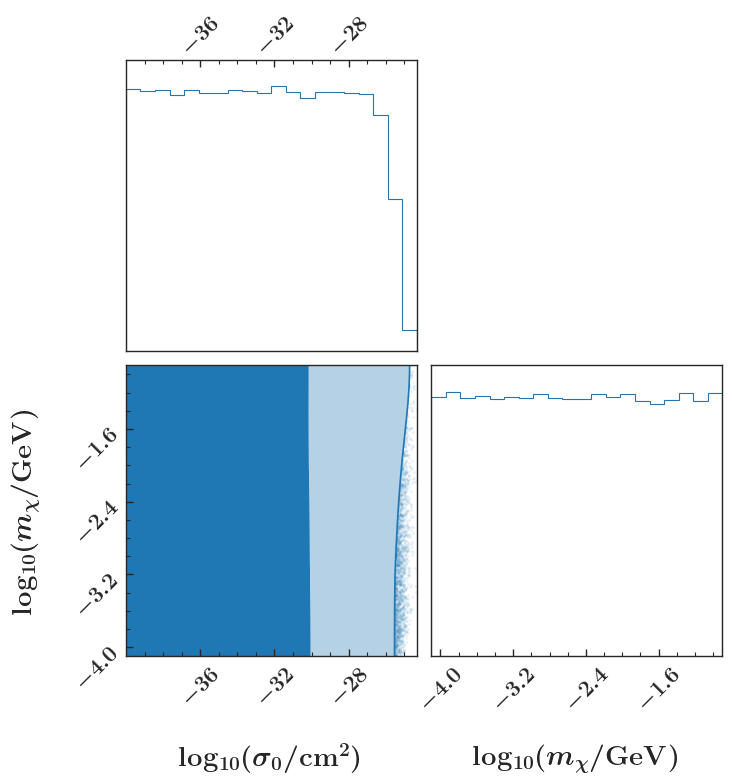

In [6]:
# create corner plot of results
paper_plot()

print(mcmc_output_001.shape)
figure = plt.figure(figsize=(8, 8))



labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_001, 
    labels=labels, 
    dpi=450, 
    smooth=4.5, 
    levels=[0.68, 0.95], 
    top_ticks=True, 
    color='#1f77b4',
    fill_contours=True,
    plot_density=True,
    #contourf_kwargs={"alpha":0.5}, 
    scatter_kws={"alpha": 0}, 
    fig=figure,
    zorder=1
);


# Access the axes of the corner plot
axes = figure.get_axes()

# Enable minor ticks and customize tick parameters for each subplot
for ax in axes:
    ax.minorticks_on()
    ax.tick_params(which='both', direction='in')
    #ax.set_xticks(np.arange(-40, -25, 3))  # Set major ticks for x-axis
    #ax.set_yticks(np.arange(-4, -0.5, 0.5))  # Set major ticks for y-axis
    ax.xaxis.set_zorder(10)  # Higher zorder for x-ticks
    ax.yaxis.set_zorder(10)  # Higher zorder for y-ticks

plt.show()
#savefig(fig, 'plots/corner_plot.png', dpi=450)

In [7]:
with open('pickled/mcmc_0.001_64_40000_fx0.5_2024-11-13_06-41-28.pkl', 'rb') as h:
    mcmc_output_05 = pickle.load(h)

(170624, 2)


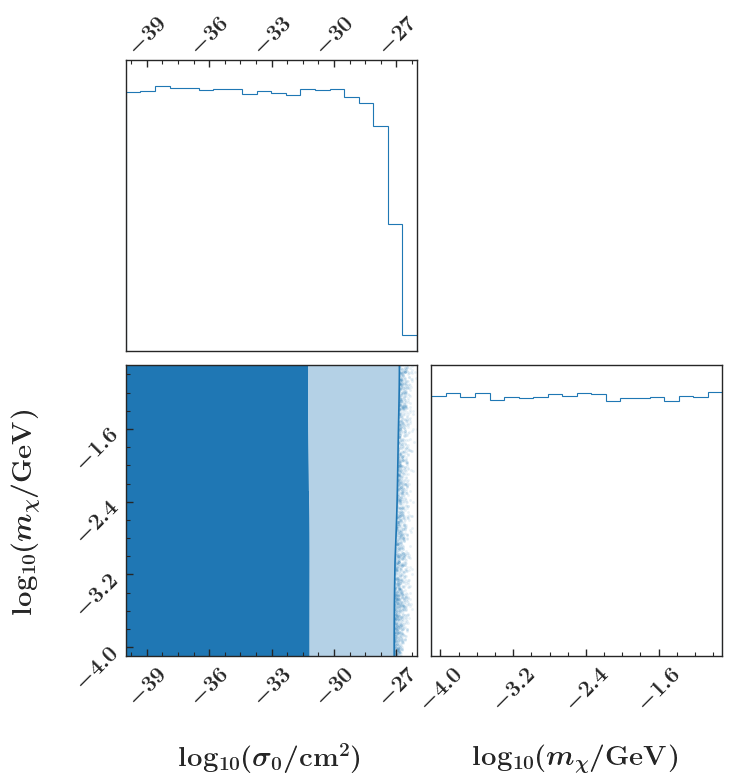

In [8]:
# create corner plot of results
paper_plot()

print(mcmc_output_05.shape)
figure = plt.figure(figsize=(8, 8))



labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_05, 
    labels=labels, 
    dpi=450, 
    smooth=4.5, 
    levels=[0.68, 0.95], 
    top_ticks=True, 
    color='#1f77b4',
    fill_contours=True,
    plot_density=True,
    #contourf_kwargs={"alpha":0.5}, 
    scatter_kws={"alpha": 0}, 
    fig=figure,
    zorder=1
);


# Access the axes of the corner plot
axes = figure.get_axes()

# Enable minor ticks and customize tick parameters for each subplot
for ax in axes:
    ax.minorticks_on()
    ax.tick_params(which='both', direction='in')
    #ax.set_xticks(np.arange(-40, -25, 3))  # Set major ticks for x-axis
    #ax.set_yticks(np.arange(-4, -0.5, 0.5))  # Set major ticks for y-axis
    ax.xaxis.set_zorder(10)  # Higher zorder for x-ticks
    ax.yaxis.set_zorder(10)  # Higher zorder for y-ticks

plt.show()
#savefig(fig, 'plots/corner_plot.png', dpi=450)

In [9]:
with open('pickled/mcmc_0.001_64_40000_2024-10-07_01-57-30.pkl', 'rb') as h:
    mcmc_output_1 = pickle.load(h)

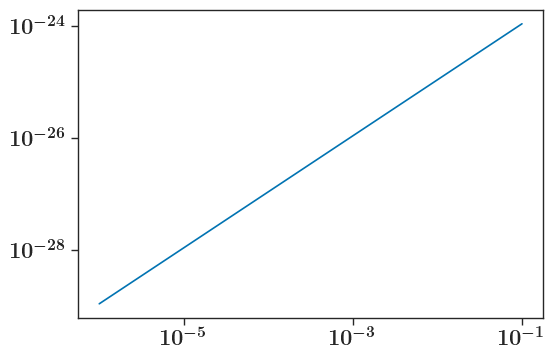

In [10]:
with open('data/prior_boundary_points.pkl', 'rb') as f:
    data = pickle.load(f)

# Unpack the dictionary into variables
mchi_values = data['mchi']
s0_max = data['max_s0']

plt.loglog(mchi_values, s0_max)

fx=0.01 avg s0:  8.199535554328728e-26
fx=0.1 avg s0:  1.0514098605617919e-26
fx=1 avg s0:  9.284775180976445e-28


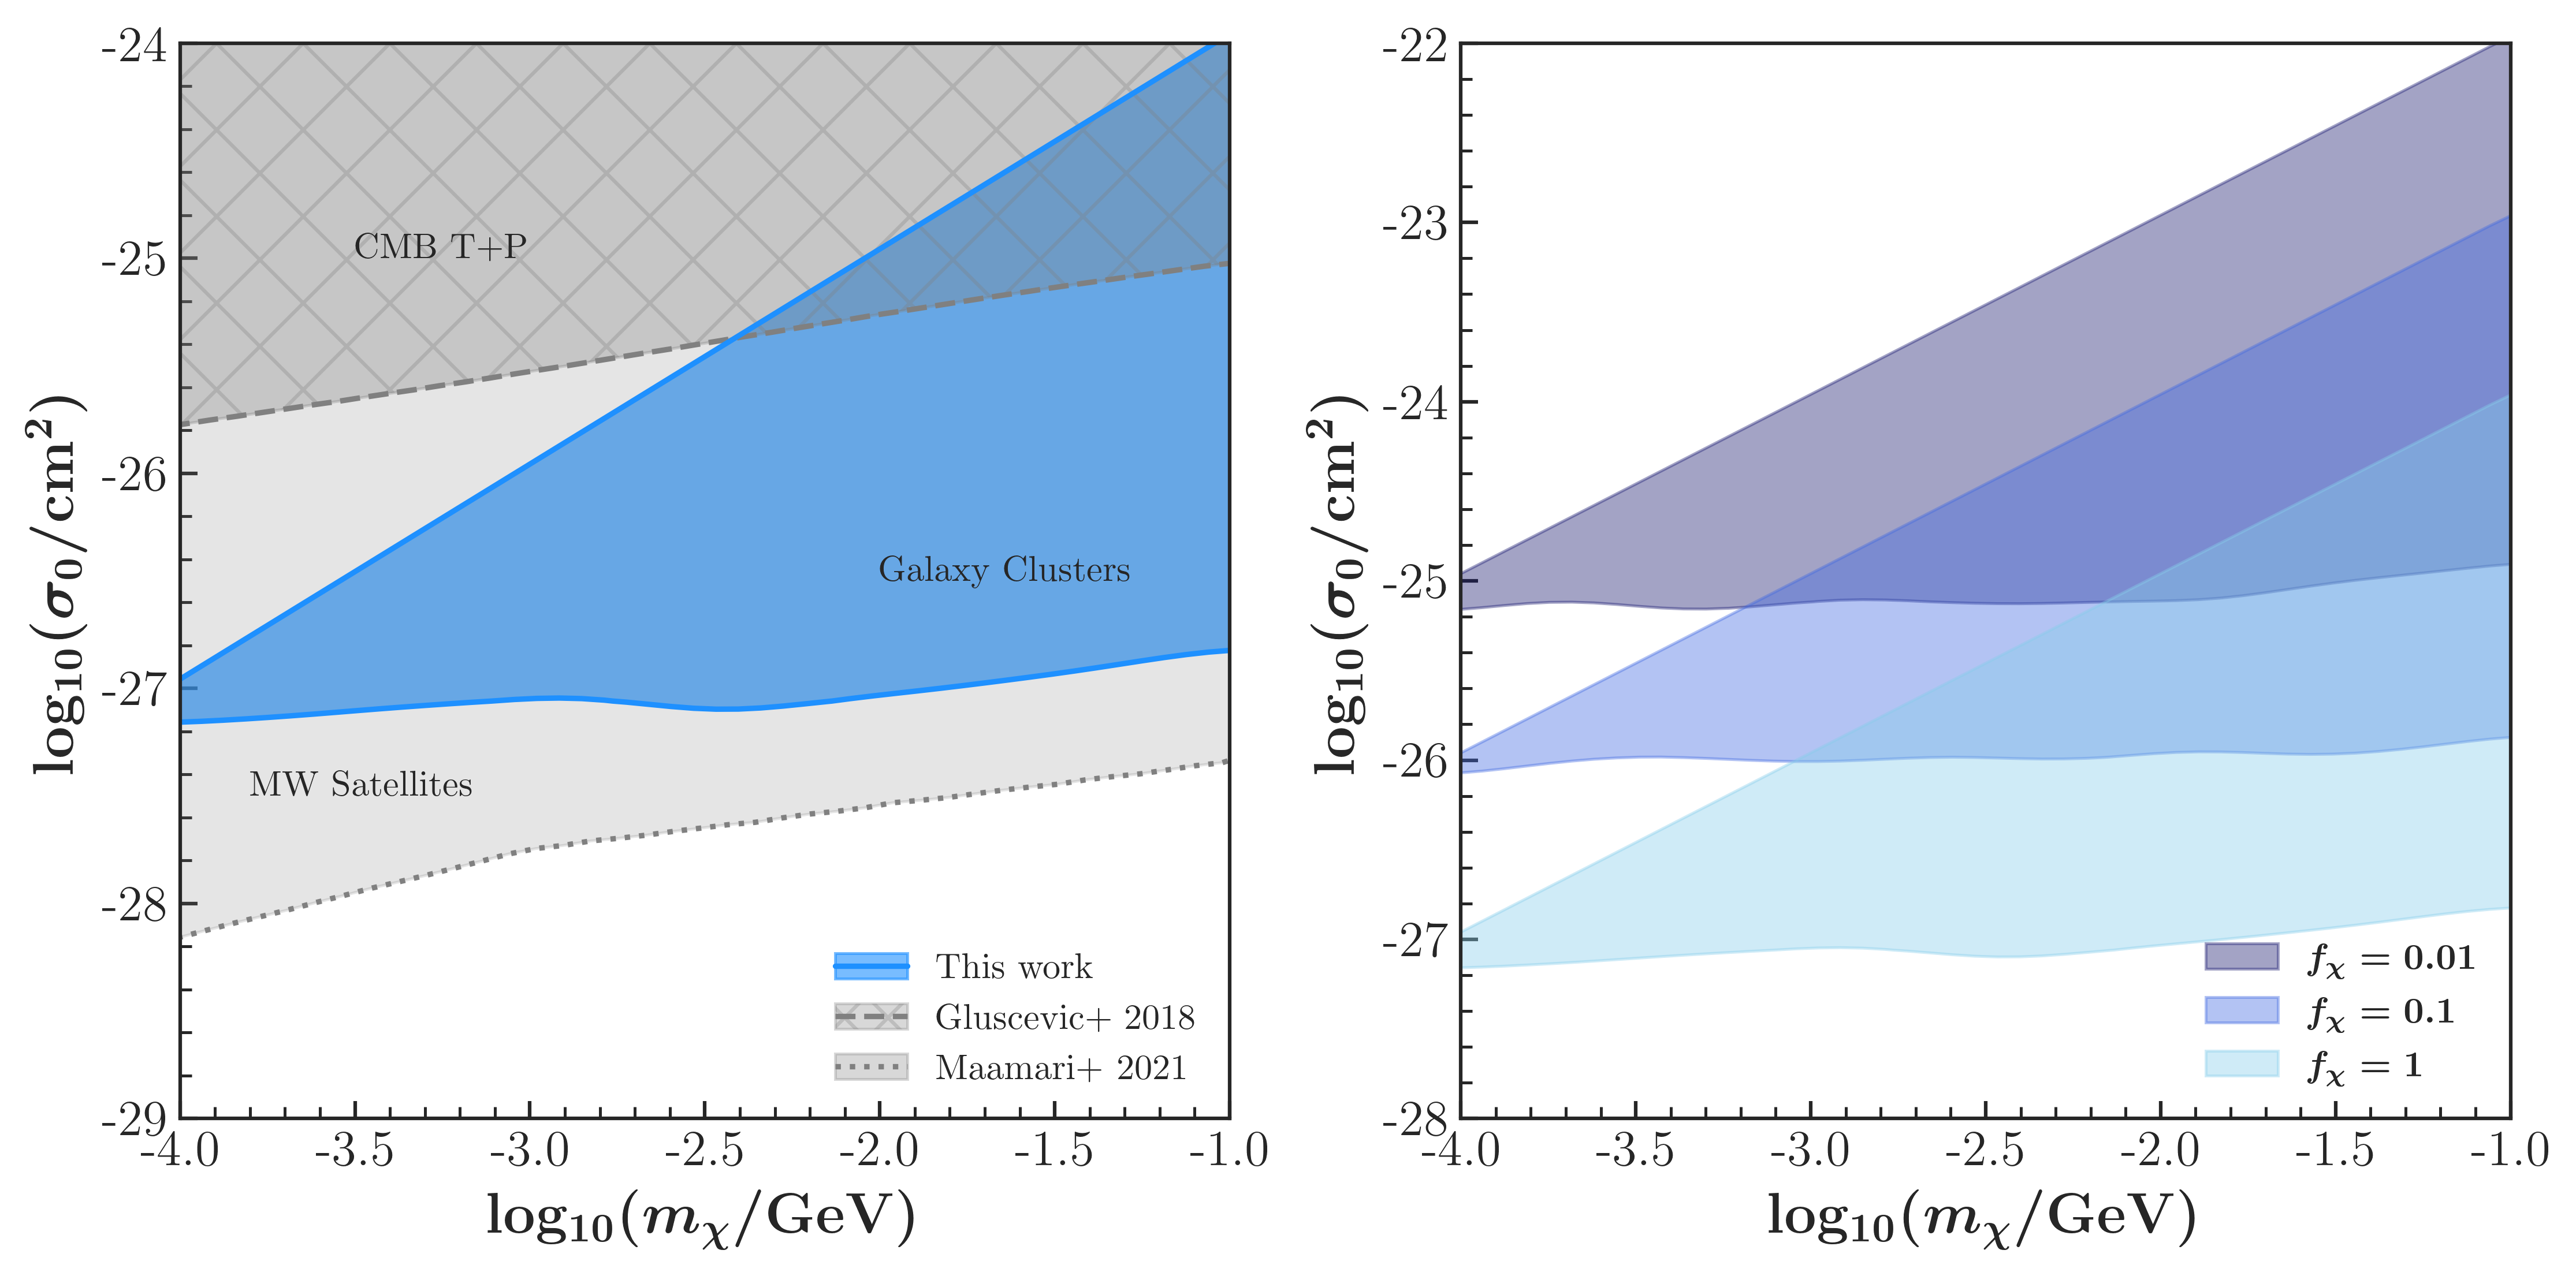

In [11]:
#plt.figure(dpi=450)
subplotsfig, (ax1, ax2) =  plt.subplots(1, 2, figsize=(10, 5), dpi=450, )
samples_coords = np.array([[x, y] for y, x in mcmc_output_1])

# Reshape to get a 2D array of samples
x_samples = samples_coords[:,0]
y_samples = samples_coords[:,1]

# Create a 2D histogram
nbins = 50
H, xedges, yedges = np.histogram2d(x_samples, y_samples, bins=nbins, density=True)

# Apply Gaussian smoothing
sigma = 3.5
H_smooth = scipy.ndimage.gaussian_filter(H, sigma=sigma)

# Compute the bin centers
xcenters = (xedges[:-1] + xedges[1:]) / 2
ycenters = (yedges[:-1] + yedges[1:]) / 2

# Create a meshgrid for the centers
X, Y = np.meshgrid(xcenters, ycenters)

# Flatten the smoothed histogram and sort the values
H_smooth_flat = H_smooth.flatten()
H_smooth_sorted = np.sort(H_smooth_flat)

# Calculate the cumulative distribution function (CDF)
cdf = np.cumsum(H_smooth_sorted)
cdf /= cdf[-1]  # Normalize


# Find the 95th percentile value
percentile_value = np.percentile(H_smooth, 5)

# Generate the contour plot
#plt.figure(dpi=450)#(figsize=(8, 6))
contour = ax1.contour(X, Y, H_smooth.T, levels=[percentile_value],colors='dodgerblue', linewidths=1.5)


path = contour.collections[0].get_paths()[0]
v = path.vertices
x = v[:,0]
y = v[:,1]

#y2=-24
y2 = np.interp(x, np.log10(mchi_values), np.log10(s0_max),)
ax1.fill_between(x, y, y2, where=(y2 >= y), interpolate=True, color='dodgerblue', alpha=0.7,)


labels = [f'$\mathrm{{This~work}}$', f"$\mathrm{{Gluscevic+ 2018}}$", f"$\mathrm{{Maamari+ 2021}}$", f"$\mathrm{{Excluded~by~prior}}$"]


# prior
ax1.plot(np.log10(mchi_values), np.log10(s0_max), color='dodgerblue', linewidth=1.5)
ax1.fill_between(
                    np.log10(mchi_values), np.log10(s0_max),
                    y2=1e-26,
                    alpha=0, color='black', 
                    hatch='//', 
                    zorder=15
                )




# load other datasets
maamari = pd.read_csv('data/maamari_2021_constraint.csv', header=None)
ax1.plot(np.log10(maamari[0]), np.log10(maamari[1]), label=f"$\mathrm{{Maamari+ 2021}}$", color='gray', linewidth=1.5, linestyle='dotted',)

ax1.fill_between(
                    np.log10(maamari[0]), np.log10(maamari[1]),
                    y2=1e-26,
                    alpha=0.2, color='gray',   #hatch='|'
                )


gluscevic = pd.read_csv('data/gluscevic_boddy_2018_velocity_independent.csv', header=None)
ax1.plot(np.log10(gluscevic[0]), np.log10(gluscevic[1]), label=f"$\mathrm{{Gluscevic+ 2018}}$", color='gray', lw=1.5, zorder=1, linestyle='dashed')



ax1.fill_between(
                    np.log10(gluscevic[0]), np.log10(gluscevic[1]),
                    y2=1e-26,
                    alpha=0.3, color='gray', hatch='x'#linewidth=2
                )





# Customize the plot
#plt.title('95th Percentile Contour Plot')
ax1.set_xlabel(r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$", size=16)
ax1.set_ylabel(r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", size=16)

# Show the plot
ax1.minorticks_on()  # Enable minor ticks
ax1.tick_params(which='both', direction='in')

ax1.set_xlim(-4, -1)
ax1.set_ylim(-29, -24)



# Define each Patch and Line2D FOR LEGEND
this_work_patch = mpatches.Patch(facecolor='dodgerblue', alpha=0.6, 
                                 #hatch='//', 
                                 edgecolor='dodgerblue')
this_work_line = Line2D([0], [0], color='dodgerblue', lw=1.5)

gluscevic_patch = mpatches.Patch(facecolor='gray', alpha=0.3, hatch='xx', edgecolor='gray')
gluscevic_line = Line2D([0], [0], color='gray', lw=1.5, linestyle='dashed')

maamari_patch = mpatches.Patch(facecolor='gray', alpha=0.3, edgecolor='gray')
maamari_line = Line2D([0], [0], color='gray', lw=1.5, linestyle='dotted')

excluded_patch = mpatches.Patch(facecolor='black', alpha=0)
excluded_line = Line2D([0], [0], color='black', lw=1.5, alpha=1)

fx_1_line = Line2D([0], [0], color='lightblue', lw=1.5, alpha=0)
fx_1_patch = mpatches.Patch(facecolor='skyblue', alpha=0.4, edgecolor='skyblue')
fx_01_line = Line2D([0], [0], color='royalblue', lw=1.5, alpha=0)
fx_01_patch = mpatches.Patch(facecolor='royalblue', alpha=0.4, edgecolor='royalblue')
fx_001_line = Line2D([0], [0], color='midnightblue', lw=1.5, alpha=0)
fx_001_patch = mpatches.Patch(facecolor='midnightblue', alpha=0.4, edgecolor='midnightblue')


ax1.text(-3.5, -25, "CMB T+P", fontsize=10)
ax1.text(-3.8, -27.5, "MW Satellites", fontsize=10)
ax1.text(-2, -26.5, 'Galaxy Clusters', fontsize=10)

# Create the handler_map using HandlerTuple for overlapping
handler_map = {
    this_work_line: HandlerLine2D(marker_pad = 0),
    gluscevic_line: HandlerLine2D(marker_pad = 0),
    maamari_line: HandlerLine2D(marker_pad = 0),
    excluded_line: HandlerLine2D(marker_pad = 0), 
    fx_01_line: HandlerLine2D(marker_pad = 0),
    fx_001_line: HandlerLine2D(marker_pad = 0)
}

# Create the legend with overlapping Patch and Line2D
ax1.legend(
    [(this_work_patch, this_work_line),
     (gluscevic_patch, gluscevic_line),
     (maamari_patch, maamari_line)],
    ["This work", "Gluscevic+ 2018", "Maamari+ 2021"],
    handler_map=handler_map,
    loc='lower right',
    frameon=False,
    fontsize=10, 
)



plot_constraint(ax2, mcmc_output_001, 'midnightblue', r"$f_\chi = 0.01$", 
                shaded=True,lines=False, fx=0.01)  
plot_constraint(ax2, mcmc_output_01, 'royalblue', r"$f_\chi=0.1$", 
                shaded=True,lines=False,fx=0.1)
plot_constraint(ax2, mcmc_output_1, 'skyblue', r"$f_\chi=1$", 
                shaded=True, lines=False, fx=1) 

plt.xlim(-4, -1)
#plt.ylim(-28, -22)
ax2.set_ylim(-28, -22)
        
ax2.set_xlabel(r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$", size=16)
#plt.ylabel(r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", size=16)
ax2.legend(
    [(fx_001_patch,fx_001_line),
    (fx_01_patch,fx_01_line),
    (fx_1_patch, fx_1_line)
    ],
    [r"$f_\chi = 0.01$", r"$f_\chi=0.1$", r"$f_\chi=1$"],
    frameon=False,
    fontsize=10, loc='lower right')

ax2.minorticks_on()  # Enable minor ticks
ax2.tick_params(which='both', direction='in')

axis_label_fontsize=14
ax1.set_xticks([-4.0, -3.5, -3.0, -2.5, -2.0, -1.5, -1.0])
ax1.set_xticklabels([-4.0, -3.5, -3.0, -2.5, -2.0, -1.5, -1.0], fontsize=axis_label_fontsize)
ax1.set_yticks([-29, -28, -27, -26, -25, -24])
ax1.set_yticklabels([-29, -28, -27, -26, -25, -24], fontsize=axis_label_fontsize)


ax2.set_xticks([-4.0, -3.5, -3.0, -2.5, -2.0, -1.5, -1.0])
ax2.set_xticklabels([-4.0, -3.5, -3.0, -2.5, -2.0, -1.5, -1.0], fontsize=axis_label_fontsize)
ax2.set_yticks([-28, -27, -26, -25, -24, -23, -22])
ax2.set_yticklabels([-28, -27, -26, -25, -24, -23, -22], fontsize=axis_label_fontsize)
ax2.set_ylabel(r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", size=16)
plt.tight_layout()
#plt.show()

#fig1=plt.gcf()
#savefig(subplotsfig, 'plots/constraints_comparison_with_fx.png', dpi=450)
